### Download data

In [1]:
data = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

!wget $data -O lead-scoring.csv

--2026-10-28 16:04:44--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘lead-scoring.csv’

lead-scoring.csv    100%[===================>] 272.21K  --.-KB/s    in 0.005s  

2026-10-28 16:04:44 (54.1 MB/s) - ‘lead-scoring.csv’ saved [278746/278746]



### Import libraries

In [3]:
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score, precision_score, recall_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

### Load data

In [4]:
df = pd.read_csv("lead-scoring.csv")

## Data preparation


In [5]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [7]:
categorical = ["lead_source", "industry", "employment_status", "location"]
numerical = ["annual_income", "number_of_courses_viewed", "interaction_count", "lead_score"]

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

In [8]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

## Question 1: ROC AUC feature importance


In [9]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [10]:
df_train = df_train.reset_index(drop=True)

In [11]:
auc_scores = []
for n in numerical:
    sort_idx = np.argsort(df_train[n])
    auc_score = roc_auc_score(df_train.converted[sort_idx], df_train[n][sort_idx])
    auc_scores.append({"feature": n, "auc": auc_score})
auc_scores = pd.DataFrame(auc_scores)
auc_scores

,feature,auc
0,annual_income,0.608198
1,number_of_courses_viewed,0.722989
2,interaction_count,0.764920
3,lead_score,0.788225


## Question 2: Training the model


In [12]:
df_val = df_val.reset_index(drop=True)
y_train = df_train.converted.values
y_val = df_val.converted.values

del df_train['converted']
del df_val['converted']

In [13]:
dv = DictVectorizer(sparse=False)

train_dict = df_train.to_dict(orient="records")
X_train = dv.fit_transform(train_dict)


In [14]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [15]:
val_dict = df_val.to_dict(orient="records")
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]

In [16]:
auc_score = roc_auc_score(y_val, y_pred)
print(f"auc : {auc_score:.3f}")

auc : 0.732


## Question 3: Precision and Recall


In [17]:
actual_positive = (y_val == 1).sum()
actual_negative = (y_val == 0).sum()
actual_positive, actual_negative, len(y_val)

(np.int64(586), np.int64(414), 1000)

In [18]:
thresholds = np.arange(0, 1.01, 0.01)
scores = []
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

for t in thresholds:
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    tn = (predict_negative & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    precision = tp / (tp + fp)
    recall = tp / (tp + fn)

    scores.append({"threshold": t, "precision": precision, "recall": recall})    
df_score = pd.DataFrame(scores)    


/tmp/ipykernel_4105/1371246406.py:16: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp / (tp + fp)


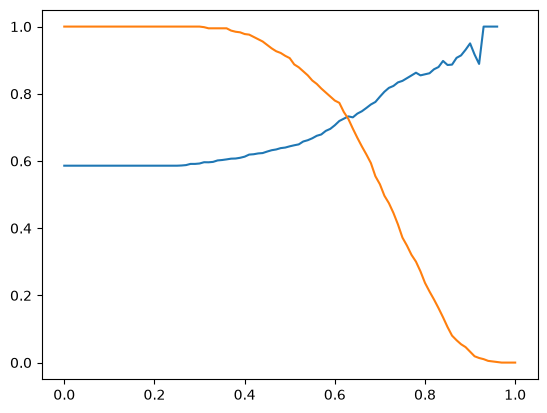

In [19]:
plt.plot(df_score.threshold, df_score.precision)
plt.plot(df_score.threshold, df_score.recall)

## Question 4: F1 score

In [20]:
df_score['F1_score'] = 2*(df_score['precision']*df_score['recall'])/(df_score['precision']+df_score['recall'])

In [21]:
a = list(df_score.F1_score.sort_values(ascending=False).index)

In [22]:
df_score[['threshold', 'F1_score']].iloc[a[0]]

threshold    0.410000
F1_score     0.757616
Name: 41, dtype: float64

## Question 5: 5-Fold CV

In [23]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [24]:
def evaluate(C):
    
    scores = []
    
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        df_train = df_train.reset_index(drop=True)
        df_val = df_val.reset_index(drop=True)
    
        y_train = df_train.converted.values
        y_val = df_val.converted.values
        
        del df_train['converted']
        del df_val['converted']
    
        train_dict = df_train.to_dict(orient="records")
        val_dict = df_val.to_dict(orient="records")
        
        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(train_dict)
        X_val = dv.transform(val_dict)
    
        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train, y_train)
    
        y_pred = model.predict_proba(X_val)[:, 1]
        
        auc= roc_auc_score(y_val, y_pred)
        scores.append(auc)

    return scores
    
scores = evaluate(0.1)
print("mean : ", round(np.mean(scores), 3), " std : ", round(np.std(scores), 3))

mean :  0.732  std :  0.007


## Question 6: Hyperparameter Tuning

In [25]:
scores1 = evaluate(0.000001)
scores2 = evaluate(0.001)
scores3 = evaluate(1)

print(f"C = {0.000001} , mean : {round(np.mean(scores1), 3)}, std : {round(np.std(scores1), 3)}")
print(f"C = {0.001} , mean : {round(np.mean(scores2), 3)}, std : {round(np.std(scores2), 3)}")
print(f"C = {1} , mean : {round(np.mean(scores3), 3)}, std : {round(np.std(scores3), 3)}")

C = 1e-06 , mean : 0.617, std : 0.019
C = 0.001 , mean : 0.749, std : 0.01
C = 1 , mean : 0.732, std : 0.007
